# Lasso Regression for DK1 Day-Ahead Prices (Option 1)
This notebook follows the structure of the course exercise *Ridge and Lasso Regression*: train on the
**training set**, tune hyperparameters on the **validation set**, evaluate once on the **test set**, and compare
unregularized, Lasso and Ridge models. Part 7 hands the chosen alpha to the team's shared benchmark.

**Question:** does a linear model that sets some coefficients to exactly zero (Lasso) forecast DK1's 24 hourly
day-ahead prices better than Ridge, and which features does it keep — especially lagged prices from Germany
(DE-LU) and the other neighbouring markets?

### Part 1 - Data Loading and Dataset Splitting

Each row is one delivery day. The 604 inputs are known at 10:00 on the day before: hourly prices of DK1, DK2,
DE-LU, NL and SE4 from the previous day (`lag1`) and the same day last week (`lag7`), hourly weather forecasts
(temperature, wind speed, cloud cover) for the five zones, and calendar terms. The target is DK1's 24 hourly
prices [EUR/MWh] of the delivery day.

For proper model development, we need three datasets:
- **Training set** (2019–2022): used to fit model parameters (coefficients)
- **Validation set** (2023): used to tune hyperparameters (feature set, regularization strength)
- **Test set** (2024): used only for final performance evaluation


Because the inputs have very different scales (prices in EUR/MWh, temperatures, cloud cover in %), they are
**standardized** — the scaler is fitted on the training set only, just like `PolynomialFeatures.fit_transform`
on the training data and `.transform` on validation and test data in the exercise.

#### Task:
Simply run this cell to get your train/validation/test splits (x_train, x_val, x_test, y_train, y_val, y_test).

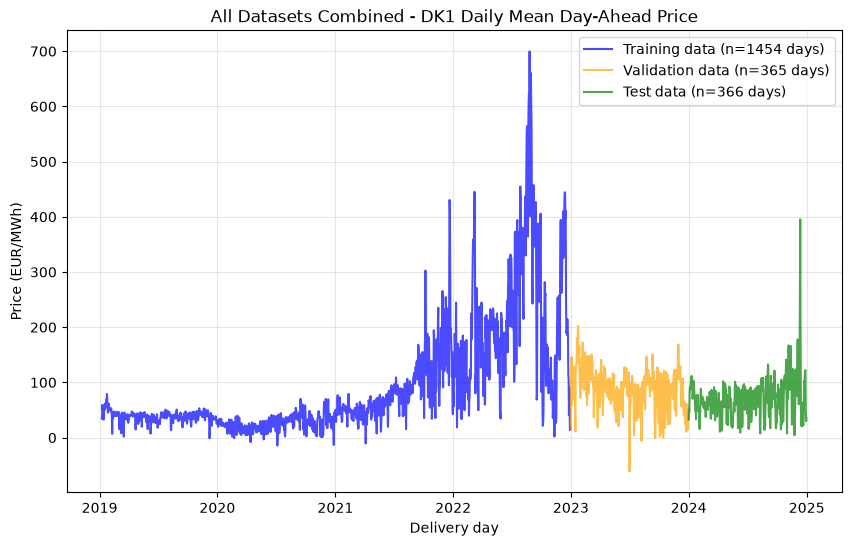

Training set size: 1454 days (2019-01-08 to 2022-12-31)
Validation set size: 365 days
Test set size: 366 days
Number of input features: 604, number of outputs (hours): 24


In [1]:
import sys
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().resolve().parents[1]          # repository root (run this notebook from team/a-lasso/)
DATA = ROOT / 'team' / 'data'

features = pd.read_csv(DATA / 'features.csv.gz', index_col='day', parse_dates=['day'])
targets = pd.read_csv(DATA / 'targets.csv.gz', index_col='day', parse_dates=['day'])

# Chronological split
train = features.index < '2023-01-01'
val = (features.index >= '2023-01-01') & (features.index < '2024-01-01')
test = features.index >= '2024-01-01'

x_train, x_val, x_test = features[train], features[val], features[test]
y_train, y_val, y_test = targets[train], targets[val], targets[test]

# Standardize: fit on the training set only
scaler = StandardScaler()
x_train_s = scaler.fit_transform(x_train)
x_val_s = scaler.transform(x_val)
x_test_s = scaler.transform(x_test)

# Plot all three datasets together (daily mean price)
plt.figure(figsize=(10, 6))
plt.plot(y_train.index, y_train.mean(axis=1), color='blue', alpha=0.7, label=f'Training data (n={len(y_train)} days)')
plt.plot(y_val.index, y_val.mean(axis=1), color='orange', alpha=0.7, label=f'Validation data (n={len(y_val)} days)')
plt.plot(y_test.index, y_test.mean(axis=1), color='green', alpha=0.7, label=f'Test data (n={len(y_test)} days)')
plt.legend()
plt.title('All Datasets Combined - DK1 Daily Mean Day-Ahead Price')
plt.xlabel('Delivery day')
plt.ylabel('Price (EUR/MWh)')
plt.grid(True, alpha=0.3)
plt.show()

print(f"Training set size: {len(x_train)} days ({x_train.index.min():%Y-%m-%d} to {x_train.index.max():%Y-%m-%d})")
print(f"Validation set size: {len(x_val)} days")
print(f"Test set size: {len(x_test)} days")
print(f"Number of input features: {x_train.shape[1]}, number of outputs (hours): {y_train.shape[1]}")

### Part 2 - Basic Linear Regression (Unregularized)
In the exercise, a 12th degree polynomial has many coefficients and overfits a small data set. Here the same
happens with an ordinary linear regression on all **604 features** fitted to only 1,454 training days.

#### Task:
Fit an unregularized linear regression on the training set and predict the validation and test sets, visualize
the results and notice any signs of overfitting. Note the test error for comparison.

Linear Regression (all 604 features):
Training RMSE: 18.1173
Validation RMSE: 37.8216
Test RMSE: 40.6380


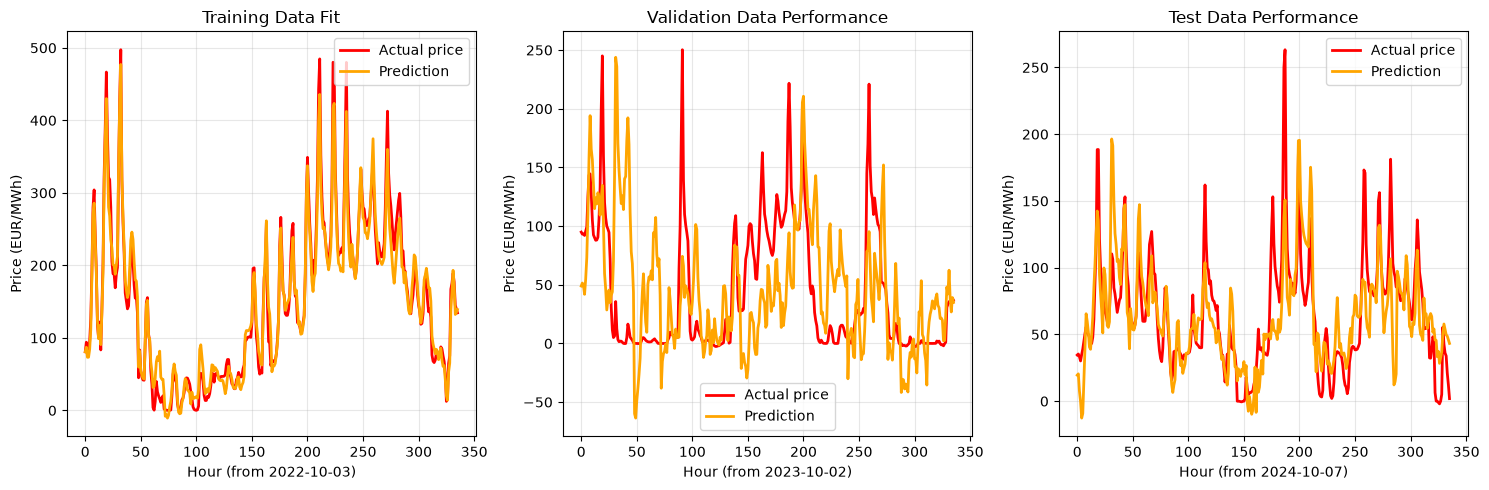

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from math import sqrt


def plot_period(ax, y_true, y_pred, start, days, title):
    """Plot actual vs predicted hourly prices for a number of consecutive days."""
    sel = (y_true.index >= start) & (y_true.index < pd.Timestamp(start) + pd.Timedelta(days=days))
    ax.plot(y_true[sel].to_numpy().ravel(), color='red', label='Actual price', linewidth=2)
    ax.plot(np.asarray(y_pred)[sel].ravel(), color='orange', label='Prediction', linewidth=2)
    ax.legend()
    ax.set_title(title)
    ax.set_xlabel(f'Hour (from {start})')
    ax.set_ylabel('Price (EUR/MWh)')
    ax.grid(True, alpha=0.3)


# Create and fit the linear regression model on TRAINING DATA ONLY
model_linear = LinearRegression()
model_linear.fit(x_train_s, y_train)

# Predict on training, validation, and test data
y_train_pred_linear = model_linear.predict(x_train_s)
y_val_pred_linear = model_linear.predict(x_val_s)
y_test_pred_linear = model_linear.predict(x_test_s)

# Calculate training, validation, and test errors
train_rmse = sqrt(mean_squared_error(y_train, y_train_pred_linear))
val_rmse = sqrt(mean_squared_error(y_val, y_val_pred_linear))
test_rmse = sqrt(mean_squared_error(y_test, y_test_pred_linear))

print(f"Linear Regression (all {x_train.shape[1]} features):")
print(f"Training RMSE: {train_rmse:.4f}")
print(f"Validation RMSE: {val_rmse:.4f}")
print(f"Test RMSE: {test_rmse:.4f}")

# Plot the results: two weeks from each set
plt.figure(figsize=(15, 5))
plot_period(plt.subplot(1, 3, 1), y_train, y_train_pred_linear, '2022-10-03', 14, 'Training Data Fit')
plot_period(plt.subplot(1, 3, 2), y_val, y_val_pred_linear, '2023-10-02', 14, 'Validation Data Performance')
plot_period(plt.subplot(1, 3, 3), y_test, y_test_pred_linear, '2024-10-07', 14, 'Test Data Performance')
plt.tight_layout()
plt.show()

### Part 3 - Hyperparameter Tuning with Validation Set

In the exercise, model complexity is the **polynomial degree**. Here it is the **feature set**: we add groups of
features step by step and use the **validation set** to find the best one. This demonstrates the proper workflow:
**train** on training set, **tune** on validation set, **evaluate** on test set.

#### Task:
Try fitting linear regressions with different feature sets on the training set and visualize the results. To
decide the optimal feature set, pick the one with the lowest validation set error. Calculate the test set error
of the optimal feature set and compare with the model that uses all features.

Testing different feature sets on validation set:
DK1 lag1           ( 24 features): Train RMSE = 36.9209, Val RMSE = 35.4561, Test RMSE = 40.7942
DK1 lag1+lag7      ( 48 features): Train RMSE = 33.3987, Val RMSE = 34.2806, Test RMSE = 38.4794
+ neighbour lags   (240 features): Train RMSE = 24.3288, Val RMSE = 38.1947, Test RMSE = 40.8971
+ calendar         (244 features): Train RMSE = 24.2203, Val RMSE = 38.0915, Test RMSE = 40.4109
+ weather (all)    (604 features): Train RMSE = 18.1173, Val RMSE = 37.8216, Test RMSE = 40.6380

**Best feature set based on validation set: DK1 lag1+lag7**

**Best feature set based on training set: + weather (all)**


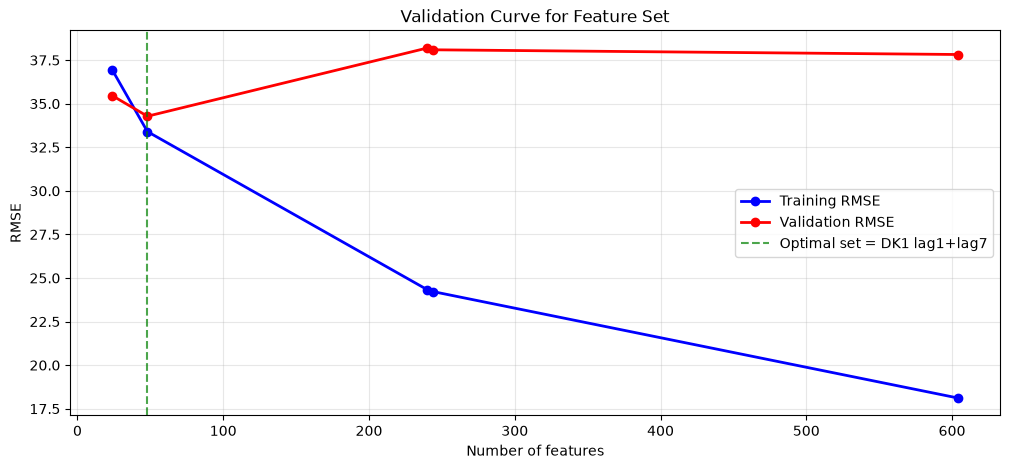

In [3]:
def columns(*prefixes):
    return [c for c in features.columns if c.startswith(prefixes)]


calendar = columns('weekday', 'year')
feature_sets = {
    'DK1 lag1': columns('DK1_lag1'),
    'DK1 lag1+lag7': columns('DK1_lag'),
    '+ neighbour lags': columns('DK1_lag', 'DK2_lag', 'DE-LU_lag', 'NL_lag', 'SE4_lag'),
    '+ calendar': columns('DK1_lag', 'DK2_lag', 'DE-LU_lag', 'NL_lag', 'SE4_lag') + calendar,
    '+ weather (all)': list(features.columns),
}
sets_to_test = list(feature_sets)
validation_errors = []
training_errors = []
test_errors = []

print("Testing different feature sets on validation set:")
print("=" * 60)

for name in sets_to_test:
    cols = [features.columns.get_loc(c) for c in feature_sets[name]]

    # Fit model
    model = LinearRegression()
    model.fit(x_train_s[:, cols], y_train)

    # Predict and calculate errors
    train_rmse_set = sqrt(mean_squared_error(y_train, model.predict(x_train_s[:, cols])))
    val_rmse_set = sqrt(mean_squared_error(y_val, model.predict(x_val_s[:, cols])))
    test_rmse_set = sqrt(mean_squared_error(y_test, model.predict(x_test_s[:, cols])))

    training_errors.append(train_rmse_set)
    validation_errors.append(val_rmse_set)
    test_errors.append(test_rmse_set)
    print(f"{name:18s} ({len(cols):3d} features): Train RMSE = {train_rmse_set:.4f}, "
          f"Val RMSE = {val_rmse_set:.4f}, Test RMSE = {test_rmse_set:.4f}")

# Find optimal feature set
optimal_set_idx = np.argmin(validation_errors)
optimal_set = sets_to_test[optimal_set_idx]
optimal_set_train = sets_to_test[np.argmin(training_errors)]
print(f"\n**Best feature set based on validation set: {optimal_set}**")
print(f"\n**Best feature set based on training set: {optimal_set_train}**")

# Plot validation curve
n_features = [len(feature_sets[n]) for n in sets_to_test]
plt.figure(figsize=(12, 5))
plt.plot(n_features, training_errors, 'bo-', label='Training RMSE', linewidth=2)
plt.plot(n_features, validation_errors, 'ro-', label='Validation RMSE', linewidth=2)
plt.axvline(x=n_features[optimal_set_idx], color='green', linestyle='--', alpha=0.7,
            label=f'Optimal set = {optimal_set}')
plt.xlabel('Number of features')
plt.ylabel('RMSE')
plt.title('Validation Curve for Feature Set')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Part 4 - Lasso Regression (L1 Regularization)

Lasso Regression performs both **regularization** and **feature selection**. It introduces an **L1 regularization**
penalty to the model, which adds the absolute value of the coefficients to the loss function. The optimization
problem for Lasso regression can be formulated as:

$$
\text{Minimize} \left( \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 + \alpha \sum_{j=1}^{p} |\beta_j| \right)
$$

where:
- $y_i$ is the true value of the target variable,
- $\hat{y}_i$ is the predicted value by the model,
- $\beta_j$ is the coefficient for the $j$-th feature,
- $\alpha$ is the **regularization parameter**. It controls the strength of the regularization.

(sklearn's `Lasso` divides the squared-error term by $2n$, so its alpha values are on a different scale from
`Ridge`'s.) With 24 target hours, sklearn fits one Lasso per hour: `coef_` has shape (24, 604), and each hour can
keep different features.

**Key Feature of Lasso**: Unlike Ridge regression, Lasso can shrink some coefficients to **exactly zero**,
effectively selecting a subset of features that contribute the most to the prediction. A **higher alpha** results
in more aggressive regularization and **more coefficients set to zero**.

**Rolling validation months.** The team protocol asks to choose alpha using only earlier *rolling* validation
months. So, unlike Parts 2–3, each alpha is evaluated like the shared benchmark: for every month of 2023, the
scaler and the Lasso are refitted on all earlier days and predict that month. The validation RMSE is computed over
the twelve predicted months (validation MAE is shown for information). The grid was fixed before looking at any
result, and 2024 is not used.

#### Task:
Perform lasso regularization on all 604 features, find the optimal alpha based on the rolling validation error and
visualize the results. Compare test error with the unregularized linear regression. Check which features are
retained, especially lagged prices from Germany and other neighbouring markets.

Testing different Lasso alpha values on rolling validation months (2023, monthly refits):
Alpha   0.030: Train RMSE = 22.9937, Val RMSE = 29.4340, Val MAE = 20.6532, Zero coefs = 8754/14496
Alpha   0.100: Train RMSE = 25.1575, Val RMSE = 27.3303, Val MAE = 18.9823, Zero coefs = 11099/14496
Alpha   0.300: Train RMSE = 27.1147, Val RMSE = 26.1363, Val MAE = 17.9110, Zero coefs = 12655/14496
Alpha   1.000: Train RMSE = 29.0140, Val RMSE = 26.3399, Val MAE = 17.8113, Zero coefs = 13549/14496
Alpha   3.000: Train RMSE = 31.5375, Val RMSE = 28.0500, Val MAE = 18.9646, Zero coefs = 13992/14496
Alpha  10.000: Train RMSE = 35.2677, Val RMSE = 31.1921, Val MAE = 21.3808, Zero coefs = 14229/14496
Alpha  30.000: Train RMSE = 47.6569, Val RMSE = 35.0482, Val MAE = 24.8199, Zero coefs = 14382/14496
Alpha 100.000: Train RMSE = 101.0186, Val RMSE = 46.0196, Val MAE = 34.6194, Zero coefs = 14479/14496

**Best Lasso alpha based on rolling validation RMSE: 0.3**


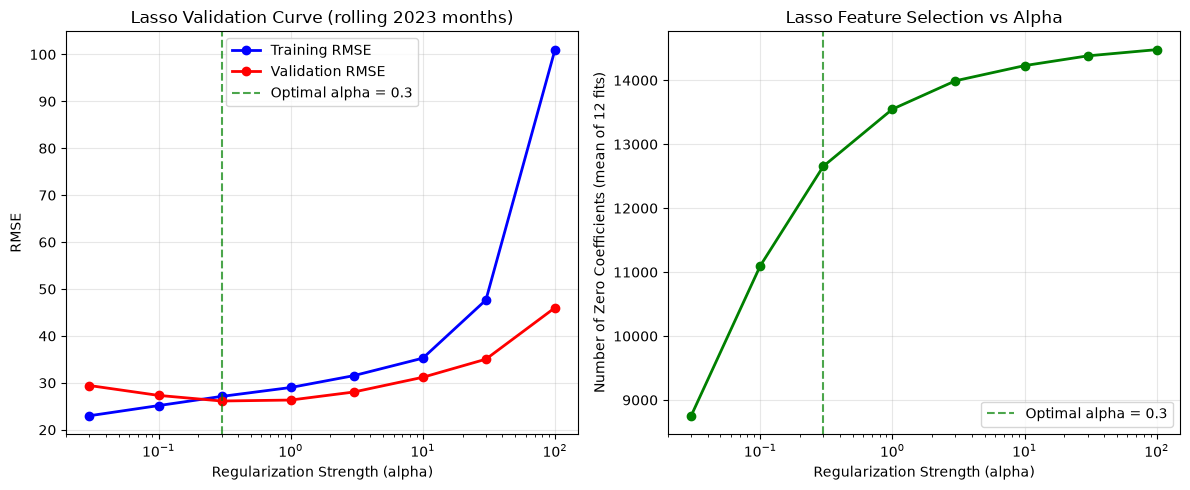

In [4]:
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error
from math import sqrt

# **LASSO HYPERPARAMETER TUNING** (rolling validation months)
# Test different alpha values to find the optimal regularization strength
# (alpha=0.03 is the team starter; alpha=0 would be the unregularized model of Part 2)
alphas_lasso = [0.03, 0.1, 0.3, 1, 3, 10, 30, 100]
val_months = pd.date_range('2023-01-01', '2024-01-01', freq='MS', inclusive='left')
lasso_train_errors = []
lasso_val_errors = []
lasso_val_mae = []
zero_counts = []

print("Testing different Lasso alpha values on rolling validation months (2023, monthly refits):")
print("=" * 60)

for alpha in alphas_lasso:
    val_preds, train_rmses, zeros = [], [], []
    for month in val_months:
        fit_days = features.index < month                                   # all earlier days
        month_days = (features.index >= month) & (features.index < month + pd.offsets.MonthBegin(1))

        scaler_m = StandardScaler()
        x_fit = scaler_m.fit_transform(features[fit_days])
        lasso = Lasso(alpha=alpha, max_iter=int(1e4))
        lasso.fit(x_fit, targets[fit_days])

        train_rmses.append(sqrt(mean_squared_error(targets[fit_days], lasso.predict(x_fit))))
        val_preds.append(pd.DataFrame(lasso.predict(scaler_m.transform(features[month_days])),
                                      index=features.index[month_days], columns=targets.columns))
        zeros.append(np.sum(lasso.coef_ == 0))

    y_val_pred = pd.concat(val_preds)
    train_rmse_a = np.mean(train_rmses)
    val_rmse_a = sqrt(mean_squared_error(y_val, y_val_pred))

    lasso_train_errors.append(train_rmse_a)
    lasso_val_errors.append(val_rmse_a)
    lasso_val_mae.append(mean_absolute_error(y_val, y_val_pred))

    # Count zero coefficients for feature selection analysis (mean over the 12 monthly fits)
    zero_coefs = np.mean(zeros)
    total_coefs = lasso.coef_.size
    zero_counts.append(zero_coefs)

    print(f"Alpha {alpha:7.3f}: Train RMSE = {train_rmse_a:.4f}, Val RMSE = {val_rmse_a:.4f}, "
          f"Val MAE = {lasso_val_mae[-1]:.4f}, Zero coefs = {zero_coefs:.0f}/{total_coefs}")

# Find optimal alpha
optimal_alpha_lasso_idx = np.argmin(lasso_val_errors)
optimal_alpha_lasso = alphas_lasso[optimal_alpha_lasso_idx]
print(f"\n**Best Lasso alpha based on rolling validation RMSE: {optimal_alpha_lasso}**")

# Plot Lasso validation curve
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.semilogx(alphas_lasso, lasso_train_errors, 'bo-', label='Training RMSE', linewidth=2)
plt.semilogx(alphas_lasso, lasso_val_errors, 'ro-', label='Validation RMSE', linewidth=2)
plt.axvline(x=optimal_alpha_lasso, color='green', linestyle='--', alpha=0.7, label=f'Optimal alpha = {optimal_alpha_lasso}')
plt.xlabel('Regularization Strength (alpha)')
plt.ylabel('RMSE')
plt.title('Lasso Validation Curve (rolling 2023 months)')
plt.legend()
plt.grid(True, alpha=0.3)

# Plot feature selection analysis (zero counts were recorded in the loop above)
plt.subplot(1, 2, 2)
plt.semilogx(alphas_lasso, zero_counts, 'go-', linewidth=2, markersize=6)
plt.axvline(x=optimal_alpha_lasso, color='green', linestyle='--', alpha=0.7, label=f'Optimal alpha = {optimal_alpha_lasso}')
plt.xlabel('Regularization Strength (alpha)')
plt.ylabel('Number of Zero Coefficients (mean of 12 fits)')
plt.title('Lasso Feature Selection vs Alpha')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Convergence check.** The starter (`alpha=0.03`, `max_iter=3000`) emits ConvergenceWarnings. We refit it on the
training window with the starter's limit and with a higher limit, and check whether the result changes.

In [5]:
import time
import warnings
from sklearn.exceptions import ConvergenceWarning

conv_rows = []
conv_preds = {}
for max_iter in [3000, 10000]:
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', ConvergenceWarning)
        t0 = time.perf_counter()
        lasso_c = Lasso(alpha=0.03, max_iter=max_iter).fit(x_train_s, y_train)
        fit_seconds = time.perf_counter() - t0
    conv_preds[max_iter] = lasso_c.predict(x_val_s)
    conv_rows.append({'max_iter': max_iter, 'iterations used (max over hours)': int(np.max(lasso_c.n_iter_)),
                      'convergence warnings': len(caught), 'non-zero coefs': int(np.sum(lasso_c.coef_ != 0)),
                      'Val RMSE': sqrt(mean_squared_error(y_val, conv_preds[max_iter])), 'fit seconds': fit_seconds})
print(pd.DataFrame(conv_rows).to_string(index=False, float_format='%.3f'))
diff = np.abs(conv_preds[3000] - conv_preds[10000])
print(f"\nPrediction difference 3000 vs 10000 iterations: mean {diff.mean():.3f}, max {diff.max():.3f} EUR/MWh")

 max_iter  iterations used (max over hours)  convergence warnings  non-zero coefs  Val RMSE  fit seconds
     3000                              3000                    21            5788    31.028       34.626
    10000                              5762                     0            5759    31.030       50.757

Prediction difference 3000 vs 10000 iterations: mean 0.042, max 0.808 EUR/MWh


Lasso Regression (alpha=0.3):
Training RMSE: 27.1709
Validation RMSE: 26.6214
Test RMSE: 30.8696
Overfitting ratio (Val/Train): 0.98
Overfitting ratio (Test/Train): 1.14

**LASSO FEATURE SELECTION RESULTS:**
Total coefficients (24 hours x 604 features): 14496
Coefficients set to EXACTLY ZERO: 12649
Non-zero coefficients: 1847 (77.0 per hour)
Features eliminated: 87.3%

Features used by at least one hour: 381 of 604
Features never used: 223

Non-zero coefficients per feature group:
                      non-zero coefs  features  non-zero per hour
SE4_lag7                         197        24               8.21
SE4_lag1                         158        24               6.58
NL_lag1                          143        24               5.96
DE-LU_wind_speed_10m              93        24               3.88
DK1_cloud_cover                   92        24               3.83
NL_lag7                           87        24               3.62
DK2_lag7                          86        24      

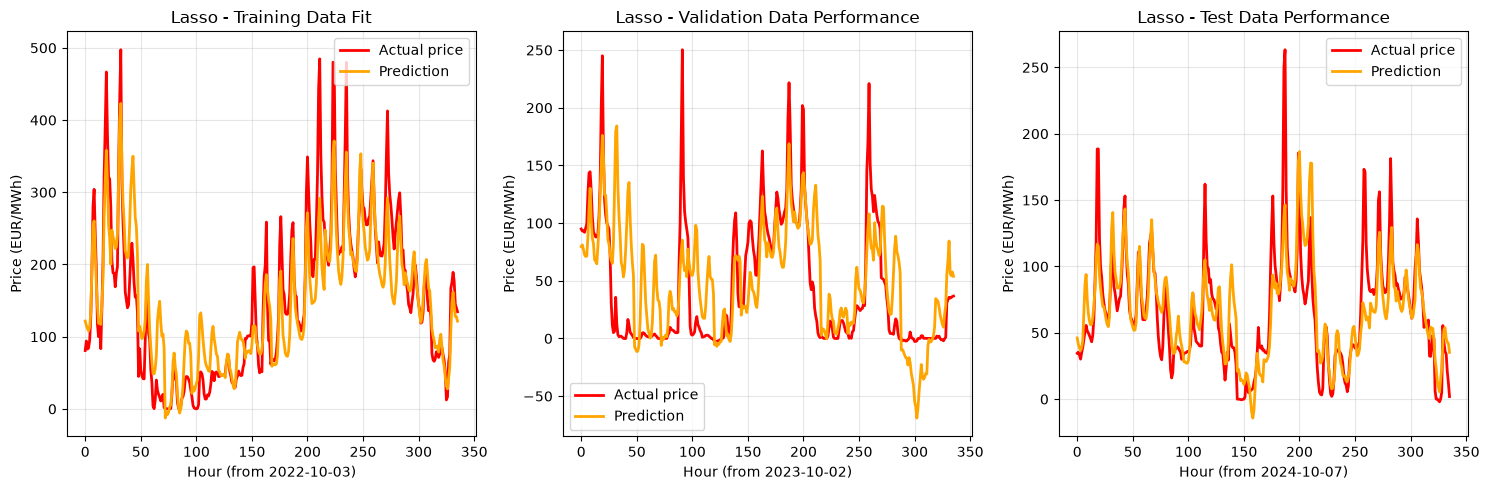

In [6]:
# Create and fit the Lasso regression model with optimal alpha
lasso_model = Lasso(alpha=optimal_alpha_lasso, max_iter=int(1e4))
lasso_model.fit(x_train_s, y_train)

# Predict on training, validation, and test data
y_train_pred_lasso = lasso_model.predict(x_train_s)
y_val_pred_lasso = lasso_model.predict(x_val_s)
y_test_pred_lasso = lasso_model.predict(x_test_s)

# Calculate training, validation, and test errors
train_rmse_lasso = sqrt(mean_squared_error(y_train, y_train_pred_lasso))
val_rmse_lasso = sqrt(mean_squared_error(y_val, y_val_pred_lasso))
test_rmse_lasso = sqrt(mean_squared_error(y_test, y_test_pred_lasso))

print(f"Lasso Regression (alpha={optimal_alpha_lasso}):")
print(f"Training RMSE: {train_rmse_lasso:.4f}")
print(f"Validation RMSE: {val_rmse_lasso:.4f}")
print(f"Test RMSE: {test_rmse_lasso:.4f}")
print(f"Overfitting ratio (Val/Train): {val_rmse_lasso/train_rmse_lasso:.2f}")
print(f"Overfitting ratio (Test/Train): {test_rmse_lasso/train_rmse_lasso:.2f}")

# **FEATURE SELECTION ANALYSIS**
zero_coefficients = np.sum(lasso_model.coef_ == 0)
total_coefficients = lasso_model.coef_.size
non_zero_coefficients = total_coefficients - zero_coefficients

print(f"\n**LASSO FEATURE SELECTION RESULTS:**")
print(f"Total coefficients (24 hours x {features.shape[1]} features): {total_coefficients}")
print(f"Coefficients set to EXACTLY ZERO: {zero_coefficients}")
print(f"Non-zero coefficients: {non_zero_coefficients} ({non_zero_coefficients / 24:.1f} per hour)")
print(f"Features eliminated: {zero_coefficients/total_coefficients*100:.1f}%")

# In how many of the 24 hour models is each feature kept?
kept = pd.Series((lasso_model.coef_ != 0).sum(axis=0), index=features.columns, name='hours kept (of 24)')
print(f"\nFeatures used by at least one hour: {(kept > 0).sum()} of {len(kept)}")
print(f"Features never used: {(kept == 0).sum()}")

# Group the 604 features: one group per zone x lag, zone x weather variable, and calendar
group = (features.columns.str.replace(r'_h\d+$', '', regex=True)
                         .str.replace('weather_', '', regex=False)
                         .str.replace(r'^(weekday|year)_(sin|cos)$', 'calendar', regex=True))
group_summary = kept.groupby(group).agg(['sum', 'size']).rename(columns={'sum': 'non-zero coefs', 'size': 'features'})
group_summary['non-zero per hour'] = group_summary['non-zero coefs'] / 24
print("\nNon-zero coefficients per feature group:")
print(group_summary.sort_values('non-zero coefs', ascending=False).to_string(float_format='%.2f'))

print("\nGerman (DE-LU) lagged prices kept by the most hour models:")
print(kept[kept.index.str.startswith('DE-LU_lag')].sort_values(ascending=False).head(10).to_string())

# Plot the results: two weeks from each set
plt.figure(figsize=(15, 5))
plot_period(plt.subplot(1, 3, 1), y_train, y_train_pred_lasso, '2022-10-03', 14, 'Lasso - Training Data Fit')
plot_period(plt.subplot(1, 3, 2), y_val, y_val_pred_lasso, '2023-10-02', 14, 'Lasso - Validation Data Performance')
plot_period(plt.subplot(1, 3, 3), y_test, y_test_pred_lasso, '2024-10-07', 14, 'Lasso - Test Data Performance')
plt.tight_layout()
plt.show()

### Part 5 - Ridge Regression (L2 Regularization)

Adding a **penalty term**, called **L2 regularization**, to handle **multicollinearity** and reduce
**overfitting**. This shrinks the magnitude of the model coefficients. The optimization problem for Ridge
regression can be formulated as:

$$
\text{Minimize} \left( \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 + \alpha \sum_{j=1}^{p} \beta_j^2 \right)
$$

Ridge regression is particularly useful when there are many **correlated features** in the dataset — here the 24
hourly values of each variable and the prices of neighbouring zones are strongly correlated. Unlike Lasso, Ridge
does **not eliminate any features**. The team's baseline is Ridge with alpha = 100.

#### Task:
Perform ridge regularization on all 604 features, find the optimal alpha based on the validation set error and
visualize the results. Compare test error with the unregularized linear regression and with Lasso.

Testing different Ridge alpha values on validation set:
Alpha      0.001: Train RMSE = 18.1201, Val RMSE = 37.6633, |Coef| sum = 659965.82
Alpha      0.010: Train RMSE = 18.2437, Val RMSE = 36.8572, |Coef| sum = 535249.99
Alpha      0.100: Train RMSE = 19.0849, Val RMSE = 35.2956, |Coef| sum = 282151.89
Alpha      1.000: Train RMSE = 20.7386, Val RMSE = 32.8560, |Coef| sum = 110015.19
Alpha     10.000: Train RMSE = 23.3155, Val RMSE = 29.6116, |Coef| sum = 39391.48
Alpha    100.000: Train RMSE = 26.6435, Val RMSE = 27.2931, |Coef| sum = 14013.61
Alpha   1000.000: Train RMSE = 30.7478, Val RMSE = 27.1949, |Coef| sum = 6254.25
Alpha  10000.000: Train RMSE = 38.3393, Val RMSE = 30.6129, |Coef| sum = 3464.42
Alpha 100000.000: Train RMSE = 51.5111, Val RMSE = 34.8168, |Coef| sum = 2373.86
Alpha 1000000.000: Train RMSE = 90.7750, Val RMSE = 42.5926, |Coef| sum = 693.36

**Best Ridge alpha based on validation set: 1000**


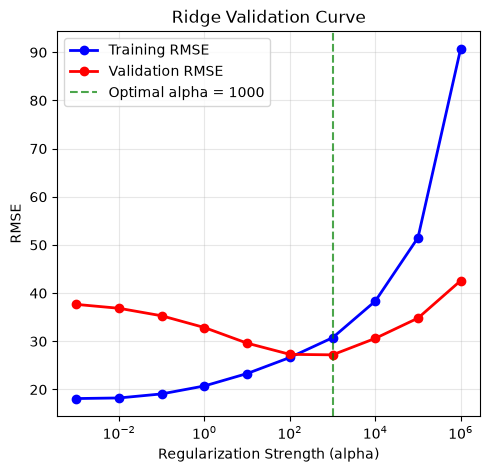

Ridge Regression (alpha=1000):
Training RMSE: 30.7478
Validation RMSE: 27.1949
Test RMSE: 31.5198
Overfitting ratio (Val/Train): 0.88
Overfitting ratio (Test/Train): 1.03


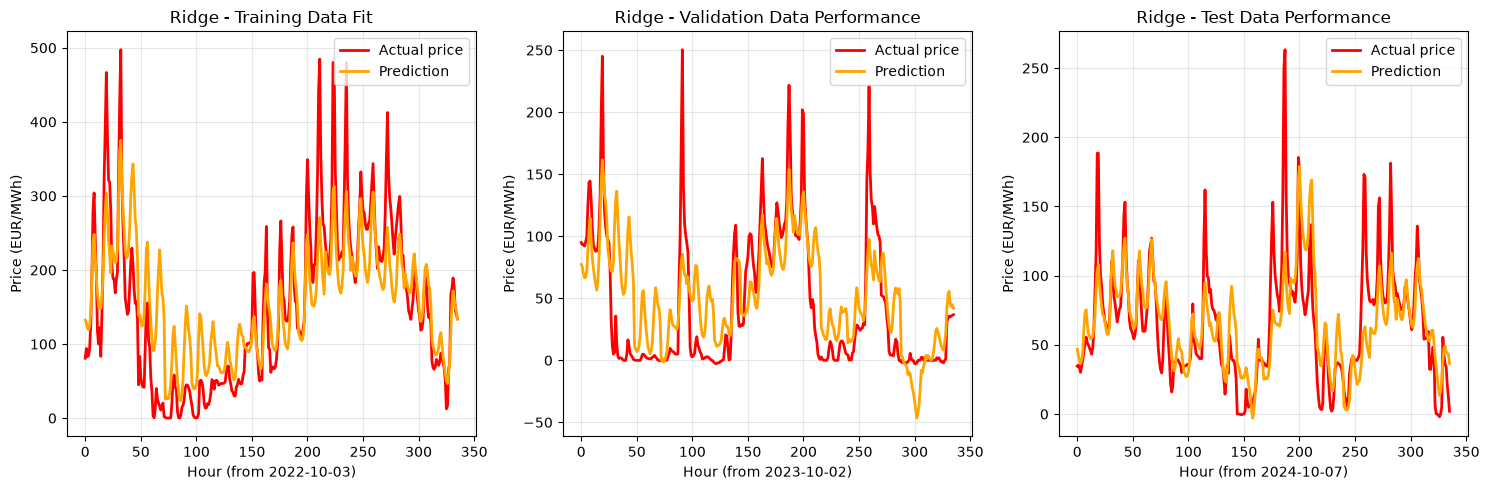

In [7]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from math import sqrt

# **RIDGE HYPERPARAMETER TUNING**
# Test different alpha values to find the optimal regularization strength
alphas_ridge = [0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000, 100000, 1000000]
ridge_train_errors = []
ridge_val_errors = []

print("Testing different Ridge alpha values on validation set:")
print("=" * 60)

for alpha in alphas_ridge:
    ridge = Ridge(alpha=alpha)
    ridge.fit(x_train_s, y_train)

    y_train_pred = ridge.predict(x_train_s)
    y_val_pred = ridge.predict(x_val_s)

    train_rmse_a = sqrt(mean_squared_error(y_train, y_train_pred))
    val_rmse_a = sqrt(mean_squared_error(y_val, y_val_pred))

    ridge_train_errors.append(train_rmse_a)
    ridge_val_errors.append(val_rmse_a)

    # Analyze coefficient magnitudes
    coef_sum = np.sum(np.abs(ridge.coef_))

    print(f"Alpha {alpha:10.3f}: Train RMSE = {train_rmse_a:.4f}, Val RMSE = {val_rmse_a:.4f}, |Coef| sum = {coef_sum:.2f}")

# Find optimal alpha
optimal_alpha_ridge_idx = np.argmin(ridge_val_errors)
optimal_alpha_ridge = alphas_ridge[optimal_alpha_ridge_idx]
print(f"\n**Best Ridge alpha based on validation set: {optimal_alpha_ridge}**")

# Plot Ridge validation curve
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.semilogx(alphas_ridge, ridge_train_errors, 'bo-', label='Training RMSE', linewidth=2)
plt.semilogx(alphas_ridge, ridge_val_errors, 'ro-', label='Validation RMSE', linewidth=2)
plt.axvline(x=optimal_alpha_ridge, color='green', linestyle='--', alpha=0.7, label=f'Optimal alpha = {optimal_alpha_ridge}')
plt.xlabel('Regularization Strength (alpha)')
plt.ylabel('RMSE')
plt.title('Ridge Validation Curve')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Create and fit the Ridge regression model with optimal alpha
ridge_model = Ridge(alpha=optimal_alpha_ridge)
ridge_model.fit(x_train_s, y_train)

# Predict on training, validation, and test data
y_train_pred_ridge = ridge_model.predict(x_train_s)
y_val_pred_ridge = ridge_model.predict(x_val_s)
y_test_pred_ridge = ridge_model.predict(x_test_s)

# Calculate training, validation, and test errors
train_rmse_ridge = sqrt(mean_squared_error(y_train, y_train_pred_ridge))
val_rmse_ridge = sqrt(mean_squared_error(y_val, y_val_pred_ridge))
test_rmse_ridge = sqrt(mean_squared_error(y_test, y_test_pred_ridge))

print(f"Ridge Regression (alpha={optimal_alpha_ridge}):")
print(f"Training RMSE: {train_rmse_ridge:.4f}")
print(f"Validation RMSE: {val_rmse_ridge:.4f}")
print(f"Test RMSE: {test_rmse_ridge:.4f}")
print(f"Overfitting ratio (Val/Train): {val_rmse_ridge/train_rmse_ridge:.2f}")
print(f"Overfitting ratio (Test/Train): {test_rmse_ridge/train_rmse_ridge:.2f}")

# Plot the results: two weeks from each set
plt.figure(figsize=(15, 5))
plot_period(plt.subplot(1, 3, 1), y_train, y_train_pred_ridge, '2022-10-03', 14, 'Ridge - Training Data Fit')
plot_period(plt.subplot(1, 3, 2), y_val, y_val_pred_ridge, '2023-10-02', 14, 'Ridge - Validation Data Performance')
plot_period(plt.subplot(1, 3, 3), y_test, y_test_pred_ridge, '2024-10-07', 14, 'Ridge - Test Data Performance')
plt.tight_layout()
plt.show()

### Part 6 - Compare Models

Let's compare all three models to see how **regularization** helps reduce **overfitting** and improves
**generalization** to new data. Examine performance on **training**, **validation**, and **test** sets. Notice how a
low training error doesn't necessarily translate to a low test error.

Model Performance Comparison:
                 Model  Training RMSE  Validation RMSE  Test RMSE  Test MAE  Val/Train Ratio  Test/Train Ratio  Non-zero coefs
Linear (Unregularized)        18.1173          37.8216    40.6380   28.6191           2.0876            2.2431           14496
    Ridge (alpha=1000)        30.7478          27.1949    31.5198   20.1189           0.8845            1.0251           14496
     Lasso (alpha=0.3)        27.1709          26.6214    30.8696   19.3263           0.9798            1.1361            1847


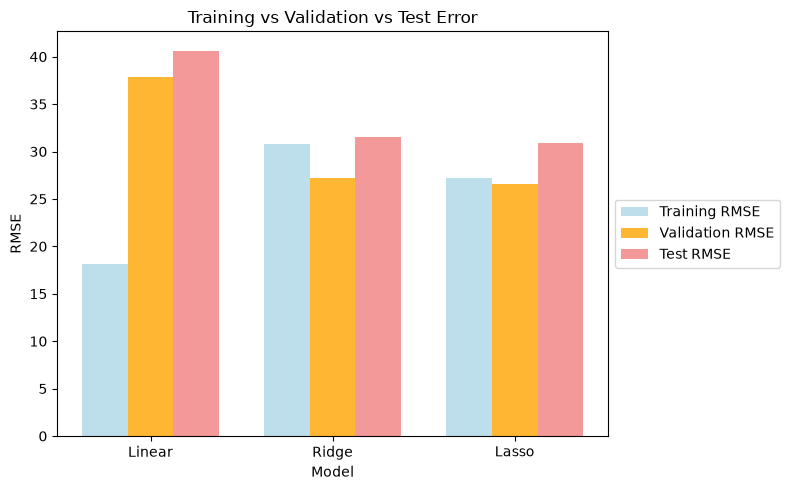

In [8]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
from math import sqrt
import pandas as pd

# Create a summary table of all models' performance
results_summary = pd.DataFrame({
    'Model': ['Linear (Unregularized)', f'Ridge (alpha={optimal_alpha_ridge})', f'Lasso (alpha={optimal_alpha_lasso})'],
    'Training RMSE': [train_rmse, train_rmse_ridge, train_rmse_lasso],
    'Validation RMSE': [val_rmse, val_rmse_ridge, val_rmse_lasso],
    'Test RMSE': [test_rmse, test_rmse_ridge, test_rmse_lasso],
    'Test MAE': [mean_absolute_error(y_test, p) for p in (y_test_pred_linear, y_test_pred_ridge, y_test_pred_lasso)],
    'Val/Train Ratio': [val_rmse/train_rmse, val_rmse_ridge/train_rmse_ridge, val_rmse_lasso/train_rmse_lasso],
    'Test/Train Ratio': [test_rmse/train_rmse, test_rmse_ridge/train_rmse_ridge, test_rmse_lasso/train_rmse_lasso],
    'Non-zero coefs': [model_linear.coef_.size, ridge_model.coef_.size, non_zero_coefficients],
})

print("Model Performance Comparison:")
print("=" * 70)
print(results_summary.to_string(index=False, float_format='%.4f'))

# Training vs Validation vs Test RMSE comparison
plt.figure(figsize=(8, 5))
models = ['Linear', 'Ridge', 'Lasso']
train_rmses = [train_rmse, train_rmse_ridge, train_rmse_lasso]
val_rmses = [val_rmse, val_rmse_ridge, val_rmse_lasso]
test_rmses = [test_rmse, test_rmse_ridge, test_rmse_lasso]

x_pos = np.arange(len(models))
width = 0.25
plt.bar(x_pos - width, train_rmses, width, label='Training RMSE', alpha=0.8, color='lightblue')
plt.bar(x_pos, val_rmses, width, label='Validation RMSE', alpha=0.8, color='orange')
plt.bar(x_pos + width, test_rmses, width, label='Test RMSE', alpha=0.8, color='lightcoral')
plt.xlabel('Model')
plt.ylabel('RMSE')
plt.title('Training vs Validation vs Test Error')
plt.xticks(x_pos, models)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

### Part 7 - Team Benchmark with the Optimal Alpha

Parts 1–6 fit each model once on 2019–2022. The team compares all models with the shared benchmark instead:
the model is **refitted at the start of every month** on all earlier days and scored on the original hourly
prices, for 2023 and 2024. The benchmark calls `build_model()` in `model.py`, so we write the optimal alpha there
and run it, together with the frozen Ridge baseline (alpha = 100). The full Lasso run takes a few minutes.

#### Task:
Write the optimal Lasso alpha into `model.py`, run the shared benchmark and compare with the Ridge baseline:
MAE, RMSE, ±5% hit rate with its eligible count, negative-price MAE and runtime.

In [9]:
model_code = "\n".join([
    '"""Sparse linear model for 24-hour DK1 price forecasts.',
    '',
    f'alpha={optimal_alpha_lasso} was chosen by the lowest rolling validation RMSE (2023 months) in lasso.ipynb.',
    '"""',
    '',
    'from sklearn.linear_model import Lasso',
    'from sklearn.pipeline import make_pipeline',
    'from sklearn.preprocessing import StandardScaler',
    '',
    '',
    'def build_model():',
    '    """Return a fresh estimator with scaling fitted inside each training window."""',
    f'    return make_pipeline(StandardScaler(), Lasso(alpha={optimal_alpha_lasso}, max_iter=10000))',
    '',
])
Path('model.py').write_text(model_code, encoding='utf-8')
print(model_code)

"""Sparse linear model for 24-hour DK1 price forecasts.

alpha=0.3 was chosen by the lowest rolling validation RMSE (2023 months) in lasso.ipynb.
"""

from sklearn.linear_model import Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def build_model():
    """Return a fresh estimator with scaling fitted inside each training window."""
    return make_pipeline(StandardScaler(), Lasso(alpha=0.3, max_iter=10000))



In [10]:
for name in ['ridge', 'lasso']:
    print(f'Running the shared benchmark for {name} ...')
    subprocess.run([sys.executable, str(ROOT / 'scripts' / 'run_team_benchmark.py'), '--model', name, '--data'],
                   cwd=ROOT, check=True, capture_output=True)

benchmark = {}
for name in ['ridge', 'lasso']:
    out = ROOT / 'results' / 'team' / name
    m = pd.read_csv(out / 'metrics.csv')
    timing = pd.read_csv(out / 'timing.csv')
    m['fit seconds (24 refits)'] = timing.fit_seconds.sum()
    m.insert(0, 'model', 'Ridge (alpha=100)' if name == 'ridge' else f'Lasso (alpha={optimal_alpha_lasso})')
    benchmark[name] = m

benchmark_table = pd.concat(benchmark.values()).sort_values(['year', 'model'])
benchmark_table[['model', 'year', 'mae', 'rmse', 'hits_5pct', 'eligible', 'rate_5pct',
                 'negative_hours', 'negative_mae', 'fit seconds (24 refits)']]

Running the shared benchmark for ridge ...
Running the shared benchmark for lasso ...


,model,year,mae,rmse,hits_5pct,eligible,rate_5pct,negative_hours,negative_mae,fit seconds (24 refits)
0,Lasso (alpha=0.3),2023,17.913169,26.138246,1691,7738,0.218532,281,30.942632,143.314173
0,Ridge (alpha=100),2023,18.780441,26.653550,1575,7738,0.203541,281,31.563195,2.991959
1,Lasso (alpha=0.3),2024,17.841657,29.351638,1429,7620,0.187533,375,19.793287,143.314173
1,Ridge (alpha=100),2024,18.339007,29.520986,1356,7620,0.177953,375,19.429686,2.991959


The aligned hourly predictions are in `results/team/lasso/predictions.csv.gz` (Git-ignored). Send them, together
with `metrics.csv` and `timing.csv`, to the lead through the team channel.